In [26]:
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns

In [27]:
nt = 1000
nx = 101

nu = 0.1 # diffusion coefficient
# nu = (0.01/math.pi)

dt = 0.001
dx = 2/ (nx - 1)

x = np.linspace(-1,1, nx)

In [28]:
x

array([-1.  , -0.98, -0.96, -0.94, -0.92, -0.9 , -0.88, -0.86, -0.84,
       -0.82, -0.8 , -0.78, -0.76, -0.74, -0.72, -0.7 , -0.68, -0.66,
       -0.64, -0.62, -0.6 , -0.58, -0.56, -0.54, -0.52, -0.5 , -0.48,
       -0.46, -0.44, -0.42, -0.4 , -0.38, -0.36, -0.34, -0.32, -0.3 ,
       -0.28, -0.26, -0.24, -0.22, -0.2 , -0.18, -0.16, -0.14, -0.12,
       -0.1 , -0.08, -0.06, -0.04, -0.02,  0.  ,  0.02,  0.04,  0.06,
        0.08,  0.1 ,  0.12,  0.14,  0.16,  0.18,  0.2 ,  0.22,  0.24,
        0.26,  0.28,  0.3 ,  0.32,  0.34,  0.36,  0.38,  0.4 ,  0.42,
        0.44,  0.46,  0.48,  0.5 ,  0.52,  0.54,  0.56,  0.58,  0.6 ,
        0.62,  0.64,  0.66,  0.68,  0.7 ,  0.72,  0.74,  0.76,  0.78,
        0.8 ,  0.82,  0.84,  0.86,  0.88,  0.9 ,  0.92,  0.94,  0.96,
        0.98,  1.  ])

In [29]:
x[0]

-1.0

In [30]:
x[1]

-0.98

In [31]:
x[0]-x[1]

-0.020000000000000018

In [32]:
dx

0.02

In [33]:
dx = abs(x[0]-x[1])


In [34]:
dx

0.020000000000000018

In [35]:
u = np.zeros(nx)
un = np.zeros(nx)

uf = np.zeros((nt,nx))

In [36]:
u = - np.sin(math.pi * x)


In [37]:
u

array([ 1.22464680e-16,  6.27905195e-02,  1.25333234e-01,  1.87381315e-01,
        2.48689887e-01,  3.09016994e-01,  3.68124553e-01,  4.25779292e-01,
        4.81753674e-01,  5.35826795e-01,  5.87785252e-01,  6.37423990e-01,
        6.84547106e-01,  7.28968627e-01,  7.70513243e-01,  8.09016994e-01,
        8.44327926e-01,  8.76306680e-01,  9.04827052e-01,  9.29776486e-01,
        9.51056516e-01,  9.68583161e-01,  9.82287251e-01,  9.92114701e-01,
        9.98026728e-01,  1.00000000e+00,  9.98026728e-01,  9.92114701e-01,
        9.82287251e-01,  9.68583161e-01,  9.51056516e-01,  9.29776486e-01,
        9.04827052e-01,  8.76306680e-01,  8.44327926e-01,  8.09016994e-01,
        7.70513243e-01,  7.28968627e-01,  6.84547106e-01,  6.37423990e-01,
        5.87785252e-01,  5.35826795e-01,  4.81753674e-01,  4.25779292e-01,
        3.68124553e-01,  3.09016994e-01,  2.48689887e-01,  1.87381315e-01,
        1.25333234e-01,  6.27905195e-02, -0.00000000e+00, -6.27905195e-02,
       -1.25333234e-01, -

In [38]:
len(u)

101

In [45]:
u

array([ 1.22464680e-16,  1.30653065e-02,  2.61178527e-02,  3.91447471e-02,
        5.21328016e-02,  6.50683620e-02,  7.79371337e-02,  9.07239984e-02,
        1.03412822e-01,  1.15986247e-01,  1.28425476e-01,  1.40710032e-01,
        1.52817504e-01,  1.64723268e-01,  1.76400194e-01,  1.87818323e-01,
        1.98944519e-01,  2.09742111e-01,  2.20170494e-01,  2.30184737e-01,
        2.39735154e-01,  2.48766893e-01,  2.57219520e-01,  2.65026629e-01,
        2.72115498e-01,  2.78406817e-01,  2.83814514e-01,  2.88245733e-01,
        2.91600999e-01,  2.93774645e-01,  2.94655543e-01,  2.94128241e-01,
        2.92074552e-01,  2.88375689e-01,  2.82915013e-01,  2.75581425e-01,
        2.66273448e-01,  2.54903950e-01,  2.41405446e-01,  2.25735809e-01,
        2.07884152e-01,  1.87876555e-01,  1.65781207e-01,  1.41712500e-01,
        1.15833553e-01,  8.83566908e-02,  5.95414873e-02,  2.96901471e-02,
       -8.59788360e-04, -3.17451486e-02, -6.25887394e-02, -9.30120946e-02,
       -1.22648475e-01, -

In [46]:
uf[0,:] = u # initial condition

In [47]:
for n in range(1, nt):
    un = u.copy()
    for i in range(1, nx-1):
        u[i] = un[i] - un[i] * (dt/dx) * (un[i] - un[i-1]) + (nu*dt/(dx**2)) * (un[i+1]-2*un[i]+un[i-1])
        uf[n,i] = u[i]

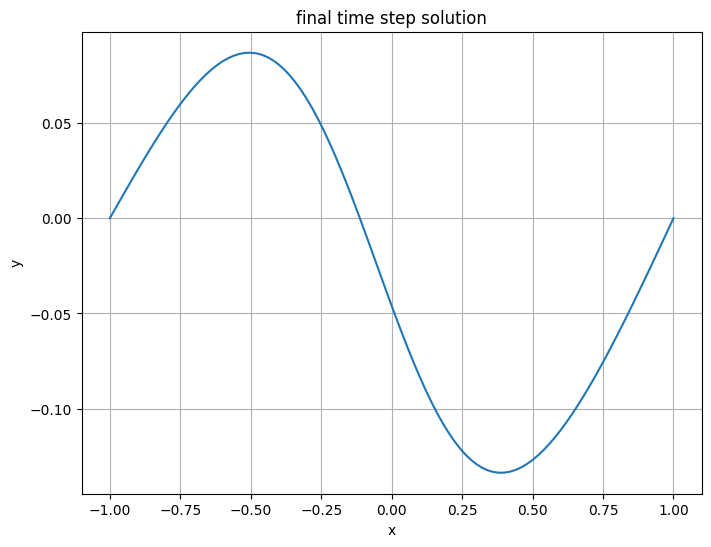

In [48]:
plt.figure(figsize=(8,6))
plt.plot(x,u, label="u solution")
plt.title("final time step solution")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

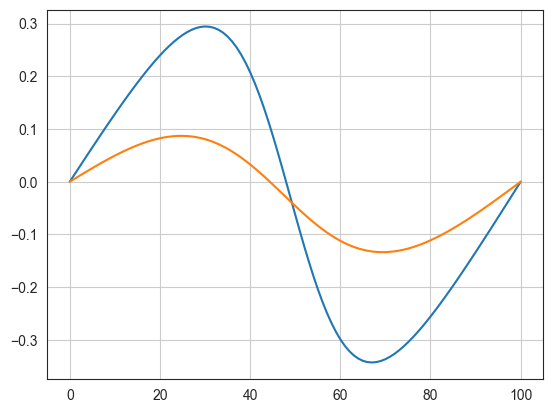

In [ ]:
plt.plot(uf[0,:])
plt.plot(uf[-1,:])
plt.grid((True))
plt.show()

In [55]:
uf

array([[ 1.22464680e-16,  1.30653065e-02,  2.61178527e-02, ...,
        -2.70621077e-02, -1.35352681e-02, -1.22464680e-16],
       [ 0.00000000e+00,  1.30535813e-02,  2.60943945e-02, ...,
        -2.70395806e-02, -1.35240065e-02,  0.00000000e+00],
       [ 0.00000000e+00,  1.30418695e-02,  2.60709631e-02, ...,
        -2.70170820e-02, -1.35127592e-02,  0.00000000e+00],
       ...,
       [ 0.00000000e+00,  5.22399340e-03,  1.04322722e-02, ...,
        -1.26826880e-02, -6.34670187e-03,  0.00000000e+00],
       [ 0.00000000e+00,  5.21870024e-03,  1.04216907e-02, ...,
        -1.26733109e-02, -6.34201230e-03,  0.00000000e+00],
       [ 0.00000000e+00,  5.21341105e-03,  1.04111171e-02, ...,
        -1.26639409e-02, -6.33732622e-03,  0.00000000e+00]])

In [56]:
uf.T

array([[ 1.22464680e-16,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.30653065e-02,  1.30535813e-02,  1.30418695e-02, ...,
         5.22399340e-03,  5.21870024e-03,  5.21341105e-03],
       [ 2.61178527e-02,  2.60943945e-02,  2.60709631e-02, ...,
         1.04322722e-02,  1.04216907e-02,  1.04111171e-02],
       ...,
       [-2.70621077e-02, -2.70395806e-02, -2.70170820e-02, ...,
        -1.26826880e-02, -1.26733109e-02, -1.26639409e-02],
       [-1.35352681e-02, -1.35240065e-02, -1.35127592e-02, ...,
        -6.34670187e-03, -6.34201230e-03, -6.33732622e-03],
       [-1.22464680e-16,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

In [57]:
sns.set_style("white")
plt.figure(figsize=(5,3), dpi=3000)
sns.heatmap(uf.T, cmap= "jet")

<Axes: >

In [59]:
# NEW CONDITIONS

nt = 1000
nx = 101

#nu = 0.1 # diffusion coefficient
nu = (0.01/math.pi)

dt = 0.001
# dx = 2/ (nx - 1)

x = np.linspace(-1,1, nx)

dx = abs(x[0] - x[1])

In [60]:
u = np.zeros(nx)
un = np.zeros(nx)

uf = np.zeros((nt,nx))

In [61]:
u = - np.sin(math.pi * x)

In [62]:
uf[0,:] = u # initial condition

In [63]:
for n in range(1, nt):
    un = u.copy()
    for i in range(1, nx-1):
        u[i] = un[i] - un[i] * (dt/dx) * (un[i] - un[i-1]) + (nu*dt/(dx**2)) * (un[i+1]-2*un[i]+un[i-1])
        uf[n,i] = u[i]

C:\Users\user\AppData\Local\Temp\ipykernel_16464\3898467365.py:4: RuntimeWarning: overflow encountered in scalar multiply
  u[i] = un[i] - un[i] * (dt/dx) * (un[i] - un[i-1]) + (nu*dt/(dx**2)) * (un[i+1]-2*un[i]+un[i-1])
C:\Users\user\AppData\Local\Temp\ipykernel_16464\3898467365.py:4: RuntimeWarning: invalid value encountered in scalar subtract
  u[i] = un[i] - un[i] * (dt/dx) * (un[i] - un[i-1]) + (nu*dt/(dx**2)) * (un[i+1]-2*un[i]+un[i-1])
C:\Users\user\AppData\Local\Temp\ipykernel_16464\3898467365.py:4: RuntimeWarning: invalid value encountered in scalar add
  u[i] = un[i] - un[i] * (dt/dx) * (un[i] - un[i-1]) + (nu*dt/(dx**2)) * (un[i+1]-2*un[i]+un[i-1])


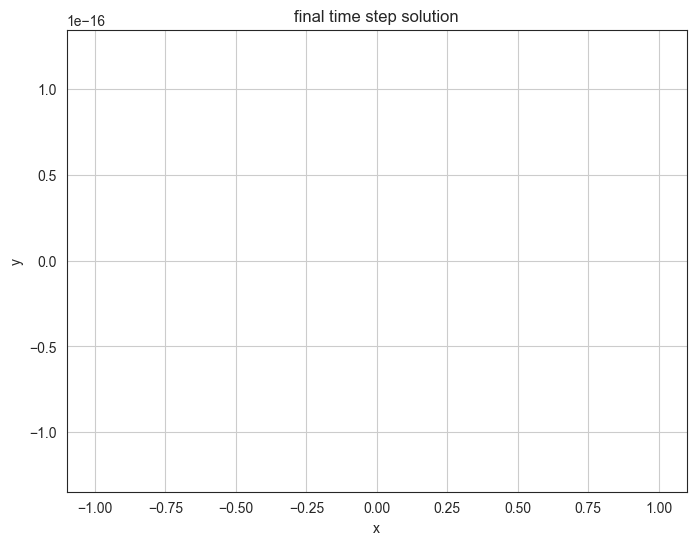

In [64]:
plt.figure(figsize=(8,6))
plt.plot(x,u, label="u solution")
plt.title("final time step solution")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

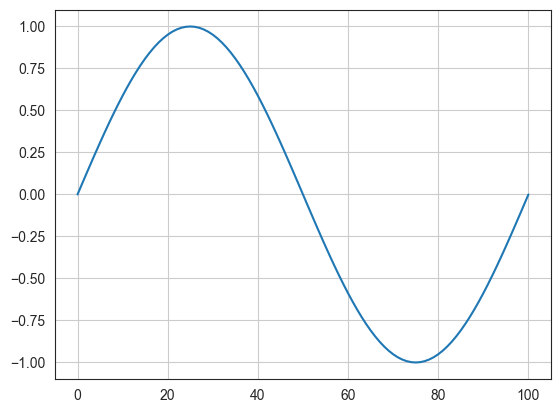

In [65]:
plt.plot(uf[0,:])
plt.plot(uf[-1,:])
plt.grid((True))
plt.show()

In [66]:
sns.set_style("white")
plt.figure(figsize=(5,3), dpi=3000)
sns.heatmap(uf.T, cmap= "jet")

<Axes: >

This method doesnt handle shocks!